# Lab 3: Regression and classification with scikit-learn

In [46]:
import numpy as np
import pandas as pd
import sklearn.linear_model as skl_lm
import matplotlib.pyplot as plt

# To get nicer plots
# from IPython.display import set_matplotlib_formats
# set_matplotlib_formats('svg') # Output as svg. Else you can try png
from IPython.core.pylabtools import figsize
figsize(10, 6) # Width and hight
np.set_printoptions(precision=3);

# Problem 3.1 Linear Regression
Implement linear regression in Python using matrix multiplications.
A matrix
$$
\textbf{X} =  \begin{bmatrix}
    1 & 2 \\
    1 & 3 \\ 
\end{bmatrix}
$$
can be constructed with numpy as `X=np.array([[1, 2], [1, 3]])` (Make sure that `numpy` has been imported. Here it is imported as `np`). The commands for matrix multiplication and transpose in `numpy` are `@` or `np.matmul` and `.T` or `np.transpose()` respectively. A system of linear equations $\textbf{A}x=\textbf{b}$ can be solved using `np.linalg.solve(A,b)`.  A $k \times k$ unit matrix can be constructed with `np.eye(k)`.


## (a) <a id='2.1-a'></a>
Assume that you record a scalar input $x$ and a scalar output $y$. First, you record $x_1 = 2, y_1 = -1$, and thereafter $x_2 = 3, y_2 = 1$. Assume a linear regression model $y = \theta_0 + \theta_1 x + \epsilon$ and learn the parameters with maximum likelihood $\widehat{\boldsymbol{\theta}}$ with the assumption $\epsilon \sim \mathcal{N}(0,\sigma_\epsilon^2)$. Use the model to predict the output for the test input $x_\star = 4$, and plot the data and the model.

theta_hat = [-5.  2.]
y_hat = 3.000


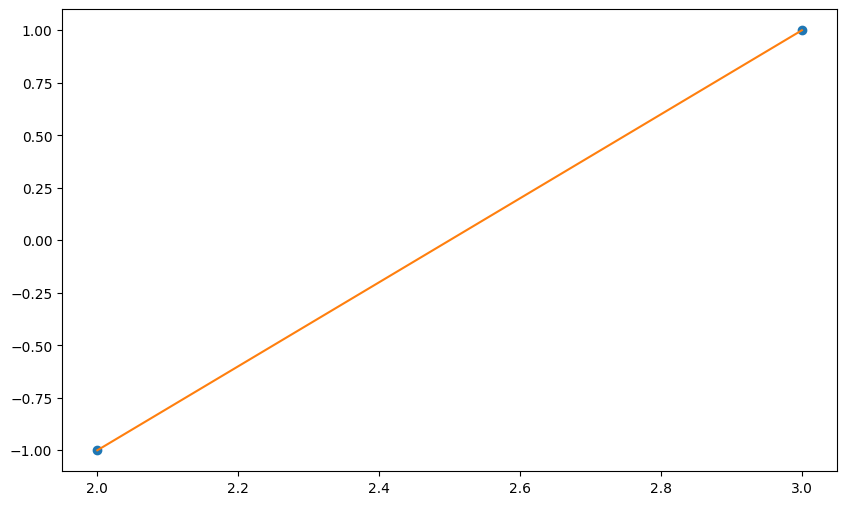

In [47]:
# Construct the data matrix
X = np.array([[1, 2],
              [1, 3]]) #TODO

y = np.array([-1, 1]) #TODO

# Solve the normal equations
theta_hat = np.linalg.solve(X.T @ X, X.T @ y) #TODO

# Print the solution
print(f"theta_hat = {theta_hat}")

# Compute prediction for x = 4
y_hat = theta_hat[0] + theta_hat[1]*4 #TODO

# Print the prediction
print(f"y_hat = {y_hat:.3f}")

# Plot the data and the model
plt.plot(X[:,1], y, 'o')
prediction = X@theta_hat
plt.plot(X[:,1], prediction);

## (b) <a id='2.1-b'></a>

Now, assume you have made a third observation $y_3 = 2$ for $x_3 = 4$ (is that what you predicted in [(a)](#2.1-a)?). Update the parameters $\widehat{\boldsymbol{\theta}}$ to all 3 data samples, add the new model to the plot (together with the new data point) and find the prediction for $x_\star = 5$.

theta_hat = [-3.833  1.5  ]
y_hat = 3.667


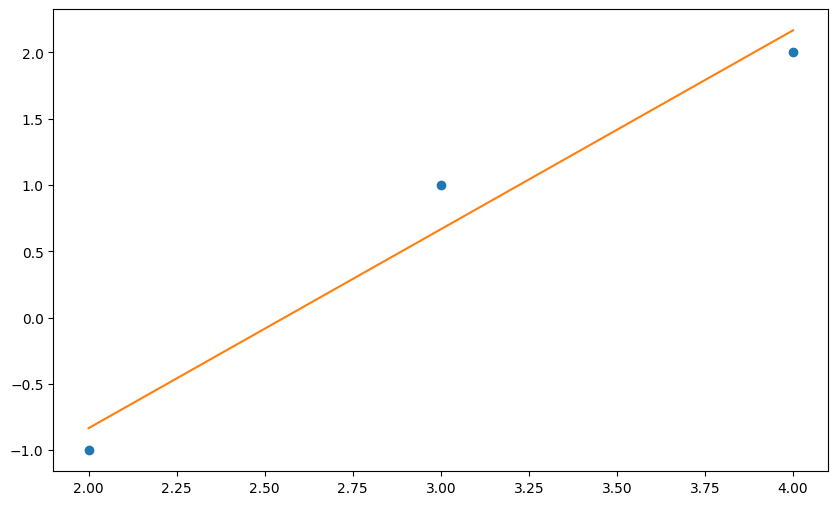

In [48]:
# Construct the data matrix (with observation x3 y3)
X = np.array([[1, 2],
              [1, 3],
              [1, 4]])  # TODO

y = np.array([-1, 1, 2])  # TODO

# Solve the normal equations
theta_hat = np.linalg.solve(X.T @ X, X.T @ y)  

# Print the solution
print(f"theta_hat = {theta_hat}")

# Compute prediction for x = 5
y_hat = theta_hat[0] + theta_hat[1]*5  # TODO

# Print the prediction
print(f"y_hat = {y_hat:.3f}")

# Plot the data and the updated model
plt.plot(X[:,1], y, 'o')
prediction = X @ theta_hat
plt.plot(X[:,1], prediction);

## (c) <a id='2.1-c'></a>
Repeat [(b)](#2.1-b), but this time using a model without intercept term, i.e., $y = \theta_1x + \epsilon$.

theta_hat = [0.31]
y_hat = 1.552


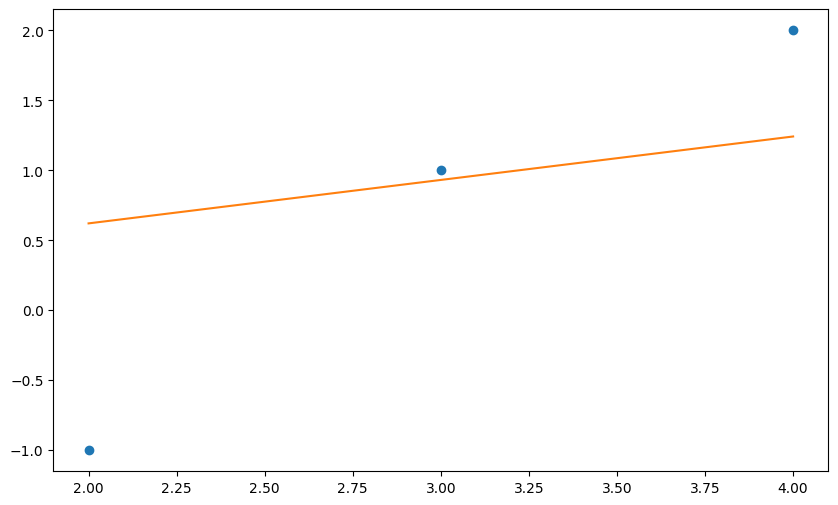

In [49]:
# Construct the data matrix (without intercept term)
X = np.array([[2],
              [3],
              [4]])  # TODO

y = np.array([-1, 1, 2])  # TODO

# Solve the normal equations
theta_hat = np.linalg.solve(X.T @ X, X.T @ y)  

# Print the solution
print(f"theta_hat = {theta_hat}")

# Compute prediction for x = 5
y_hat = theta_hat[0] * 5  

# Print the prediction
print(f"y_hat = {y_hat:.3f}")

# Plot the data and the model
plt.plot(X[:,0], y, 'o')
prediction = X @ theta_hat
plt.plot(X[:,0], prediction);


## (d) <a id='2.1-d'></a>
Repeat [(b)](#2.1-b), but this time using Ridge Regression with $\gamma=1$ instead.

theta_hat = [-0.538  0.462]
y_hat = 1.769


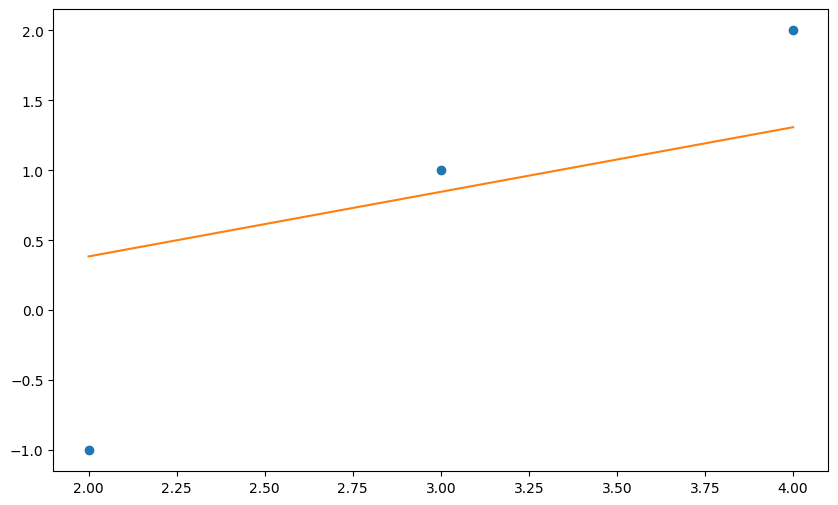

In [50]:
# Construct the data matrix (with intercept)
X = np.array([[1, 2],
              [1, 3],
              [1, 4]])  # TODO

y = np.array([-1, 1, 2])  # TODO

gamma = 1  # Ridge parameter

# Solve the ridge normal equations: (X^T X + gamma I) theta = X^T y
I = np.eye(X.shape[1])  # 2x2 identity matrix
theta_hat = np.linalg.solve(X.T @ X + gamma * I, X.T @ y)  # TODO

# Print the solution
print(f"theta_hat = {theta_hat}")

# Compute prediction for x = 5
y_hat = theta_hat[0] + theta_hat[1]*5  # TODO

# Print the prediction
print(f"y_hat = {y_hat:.3f}")

# Plot the data and the model
plt.plot(X[:,1], y, 'o')
prediction = X @ theta_hat
plt.plot(X[:,1], prediction);


# 3.2 Problem 2.1 using the linear_model.LinearRegression() command
Implement the linear regression problem from Lab 3.1(b) and (c) using the command `LinearRegression()` from `sklearn.linear_model`. 

## (b)
[See above.](#2.1-b)

The coeficient for X is : 1.500
The offset is:  -3.833


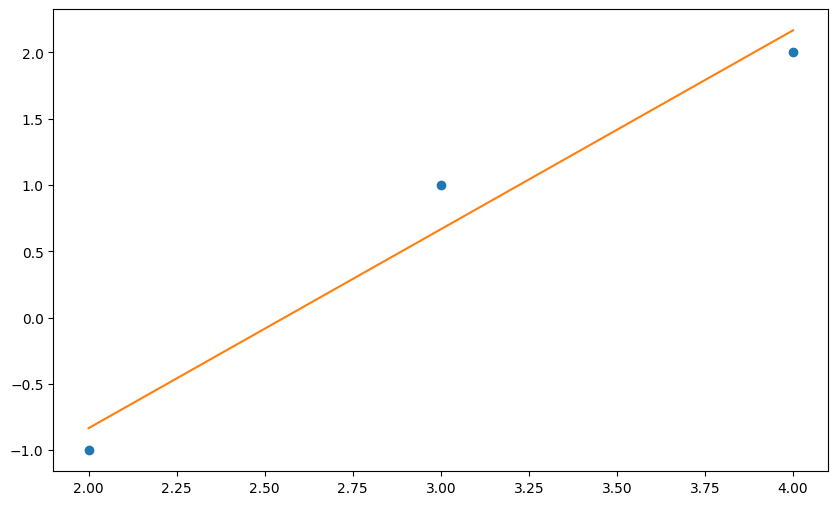

In [51]:
# copy from above and take a look how to use LinearRegression()

X = np.array([[2],
              [3],
              [4]])  # TODO

y = np.array([-1, 1, 2])  # TODO

# Learn the model using the skl_lm() command
model = skl_lm.LinearRegression()
model.fit(X, y)

# Print the solution
print(f'The coeficient for X is : {model.coef_[0]:.3f}')
print(f'The offset is:  {model.intercept_:.3f}') # TODO

# Plot the data and the model
plt.plot(X, y, 'o')
prediction =  X @ model.coef_ + model.intercept_
plt.plot(X, prediction);

## (c)
[See above.](#2.1-c)

The coeficient for X is : 0.310
The offset is:  0


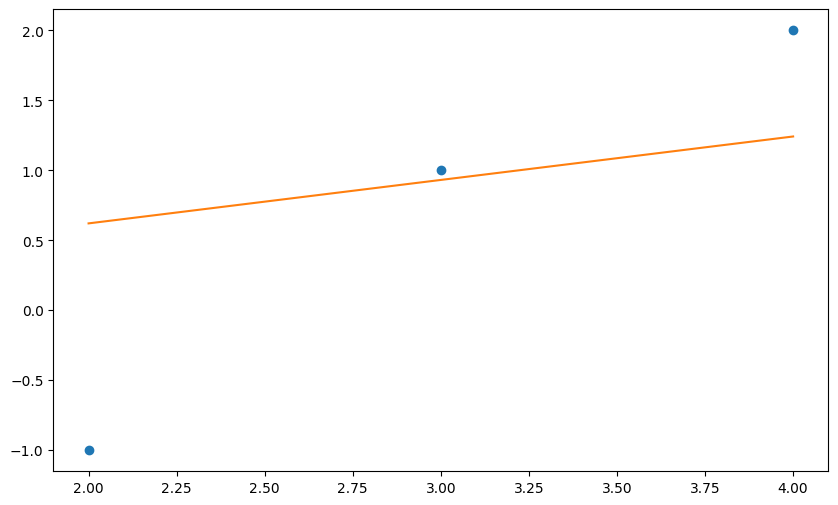

In [52]:
# copy from above and take a look how to use LinearRegression()

X = np.array([[2],
              [3],
              [4]])  # TODO

y = np.array([-1, 1, 2])  # TODO

# Learn the model using the skl_lm() command (NO intercept)
model = skl_lm.LinearRegression(fit_intercept=False)
model.fit(X, y)

# Print the solution
print(f'The coeficient for X is : {model.coef_[0]:.3f}')
print(f'The offset is:  0')  # no intercept by definition

# Plot the data and the model
plt.plot(X, y, 'o')
prediction = X @ model.coef_   # no intercept term
plt.plot(X, prediction)

# 3.3 The Auto data set

## (a)
Load the dataset `'data/auto.csv'`. Familiarize yourself with the dataset using `auto.info()`. The dataset:  

**Description**:  Gas mileage, horsepower, and other information for 392 vehicles.  
**Format**: A data frame with 392 observations on the following 9 variables.  

- `mpg`: miles per gallon  
- `cylinders`: Number of cylinders between 4 and 8
- `displacement`: Engine displacement (cu. inches)
- `horsepower`: Engine horsepower
- `weight`: Vehicle weight (lbs.)
- `acceleration`: Time to accelerate from 0 to 60 mph (sec.)
- `year`: Model year (modulo 100)
- `origin`: Origin of car (1. American, 2. European, 3. Japanese)
- `name`: Vehicle name  
*The orginal data contained 408 observations but 16 observations with missing values were removed.*


In [53]:
# Load library
# The null values are '?' in the dataset. `na_values="?"` recognize the null values. 
# There are null values that will mess up the computation. Easier to drop them by `dropna()`.

# url = 'data/auto.csv'
url = 'https://uu-sml.github.io/course-sml-public/data/auto.csv'

auto = pd.read_csv(url, na_values='?').dropna()

auto.info()

<class 'pandas.DataFrame'>
Index: 392 entries, 0 to 396
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           392 non-null    float64
 1   cylinders     392 non-null    int64  
 2   displacement  392 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        392 non-null    int64  
 5   acceleration  392 non-null    float64
 6   year          392 non-null    int64  
 7   origin        392 non-null    int64  
 8   name          392 non-null    str    
dtypes: float64(4), int64(4), str(1)
memory usage: 30.6 KB


## (b)
Divide the data set randomly into two approximately equally sized subsets, `train` and `test` by generating the random indices using `np.random.choice()`.

In [65]:
# random training set, half the data
train_idx = np.random.choice(len(auto), size=len(auto)//2, replace=False)

# remaining test set
test_idx = np.setdiff1d(np.arange(len(auto)), train_idx)

# the train and test datasets
train = auto.iloc[train_idx]
test = auto.iloc[test_idx]

print(len(train), len(test))

196 196


## (c)
Perform linear regression with `mpg` as the output and all other variables except name as input. How well (in terms of root-mean-square-error) does the model perform on test data and training data, respectively?


In [66]:
# Ignore RuntimeWarning: internal gelsd driver lwork query error. Harmless
from sklearn.metrics import root_mean_squared_error

# Linear regression
model = skl_lm.LinearRegression() # TODO
X_train = train[['cylinders', 'displacement', 'horsepower', 'weight',\
                 'acceleration', 'year', 'origin']]
Y_train = train['mpg']
model.fit(X_train, Y_train) # TODO
print(model)

# Evaluate on training data
# check sklearn.metrics.root_mean_squared_error() to measure the error
train_predict = model.predict(X_train) # TODO
train_RMSE = root_mean_squared_error(Y_train, train_predict)
print(f'Train RMSE:\t{train_RMSE:.3f}') # TODO

## Evaluate on test data
X_test = test[['cylinders', 'displacement', 'horsepower', 'weight',
               'acceleration', 'year', 'origin']] # TODO
Y_test = test['mpg']
# ksk lägga till Y_test vore fint
test_predict = model.predict(X_test) # TODO
test_RMSE = root_mean_squared_error(Y_test, test_predict)
print(f'Test RMSE:\t{test_RMSE:.3f}')# TODO


LinearRegression()
Train RMSE:	3.224
Test RMSE:	3.390


# 3.4 Nonlinear transformations of input variables

In [56]:
#Start by running the following code to generate your training data
np.random.seed(1)
x_train = np.random.uniform(0, 10, 100)
y_train = .4 \
          - .6 * x_train \
          + 3. * np.sin(x_train - 1.2) \
          + np.random.normal(0, 0.1, 100)

## (a) 
Plot the training output `y_train` versus the training input `x_train`.  

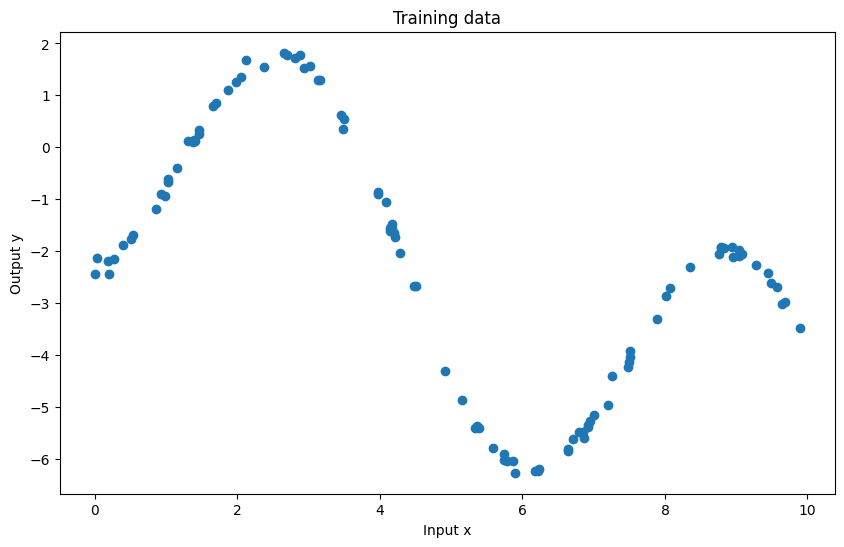

In [57]:
# Plot
plt.plot(x_train, y_train, 'o')
plt.title('Training data')
plt.xlabel('Input x')
plt.ylabel('Output y');

## (b) 
Learn a model on the form 
$$
y= a + bx + c \sin(x + \phi) + \epsilon,  \qquad  \epsilon \sim \mathcal{N}(0, 0,1^2) \qquad (3.1)
$$

where all parameters $a$, $b$, $c$ and $\phi$ are to be learned from the training data `x_train` and `y_train`. Refrain from using the` linear_model()` command, but implement the normal equations yourself as in problem 2.1. Hint: Even though (2.1) is not a linear regression model, you can use the fact that $c \sin(x + \phi) = c \cos(\phi) \sin(x) + c \sin(\phi) \cos(x)$ to transform it into one.  



In [58]:
X_train = np.column_stack([np.ones(100), x_train, np.sin(x_train), np.cos(x_train)]) # TODO a+b+alpha sin(x)+beta cos(x) 

# Solve normal equations: (X^T X) theta = X^T y
theta_hat = np.linalg.solve(X_train.T @ X_train, X_train.T @ y_train) # TODO
print(f'theta_hat ={theta_hat}')

theta_hat =[ 0.421 -0.603  1.088 -2.789]


## (c) 
Construct 100 test inputs `x_test` in the span from 0 to 10 by using the `np.linspace()` function. Predict the outputs corresponding to these inputs and plot them together with the training data.

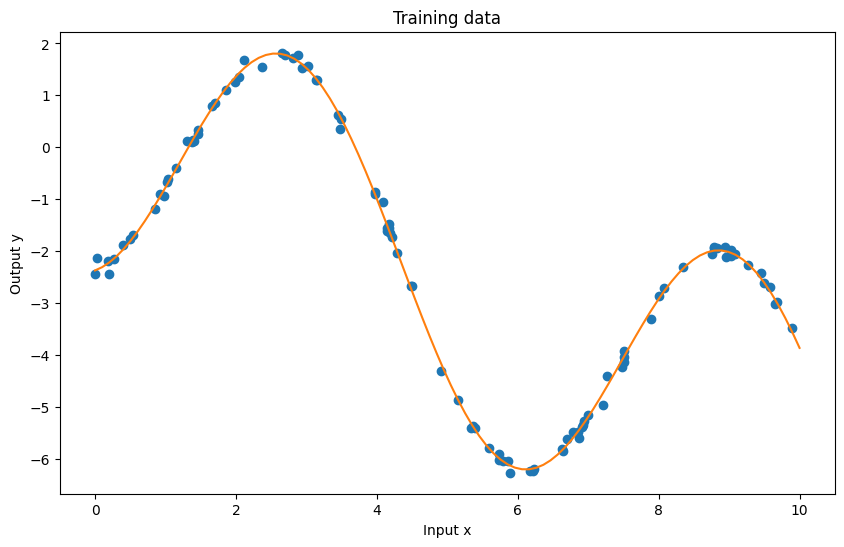

In [59]:
# Construct test inputs
x_test = np.linspace(0, 10, 100)

# Design matrix for test data (same features as training!)
X_test = np.column_stack([ np.ones(100),x_test,np.sin(x_test),np.cos(x_test)])

# Predict outputs
y_test = X_test @ theta_hat

# Plot training data and model prediction
plt.plot(x_train, y_train, 'o')
plt.plot(x_test, y_test, '-')
plt.title('Training data')
plt.xlabel('Input x')
plt.ylabel('Output y')
plt.show();

## (d) 
Do a least squares fit by instead using the `linear_model()` function in `Python`. Check that you get the same estimates as in (b).

In [60]:
X_train = np.column_stack([np.ones(100), x_train, np.sin(x_train), np.cos(x_train)]) # TODO a+b+alpha sin(x)+beta cos(x) 

# Fit with sklearn (IMPORTANT: intercept already included in X)
model = skl_lm.LinearRegression(fit_intercept=False)
model.fit(X_train, y_train)

theta_sklearn = model.coef_
print(f"theta_hat (manual)  = {theta_hat}")
print(f"theta_hat (sklearn) = {theta_sklearn}")

# Check difference
print(f"max abs diff = {np.max(np.abs(theta_hat - theta_sklearn)):.3e}")

theta_hat (manual)  = [ 0.421 -0.603  1.088 -2.789]
theta_hat (sklearn) = [ 0.421 -0.603  1.088 -2.789]
max abs diff = 1.776e-15


# 3.5  Regularization

In this exercise we will apply Ridge regression and Lasso for fitting a polynomial to a scalar data set. We will have a setting where we first generate synthetic training data from 
<a id=2.2></a>
$$
y = x^3 + 2x^2 + 6 + \epsilon, \qquad (3.2)
$$
and later try to learn model for the data.   

## (a) <a id='2.5-a'></a>
Write a function that implements the polynomial [(2.2)](#2.2), i.e., takes $x$ as argument and returns $x^3 + 2x^2 + 6$. 

In [69]:
def f(x):
    return x**3 + 2*x**2 + 6 # TODO

## (b) 
Use `np.random.seed()` to set the random seed. Use the function `np.linspace()` to construct a vector `x` with `n = 12` elements equally spaced from $-2.3$ to $1$. Then use your function from [(a)](#2.5-a) to construct a vector $\textbf{y} = [y_1, ..., y_n]^T$ with 12 elements, where $y = x^3 + 2x^2 + 6 + \epsilon$, with $\epsilon \sim  \mathcal{N(0, 1^2)}$. This is our training data.

In [68]:
np.random.seed(0)
x_train = np.linspace(-2.3, 1, 12) # TODO # Construct x with n = 12 points from -2.3 to 1
y_train = f(x_train) + np.random.normal(0, 1, 12) # TODO # Generate noisy observations

## (c) 
Plot the training data $\mathcal{T} = \{(x_i, y_i)\}_{i=1}^{12}$ together with the "true" function.

C:\Users\enzov\AppData\Local\Temp\ipykernel_4256\1419004629.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


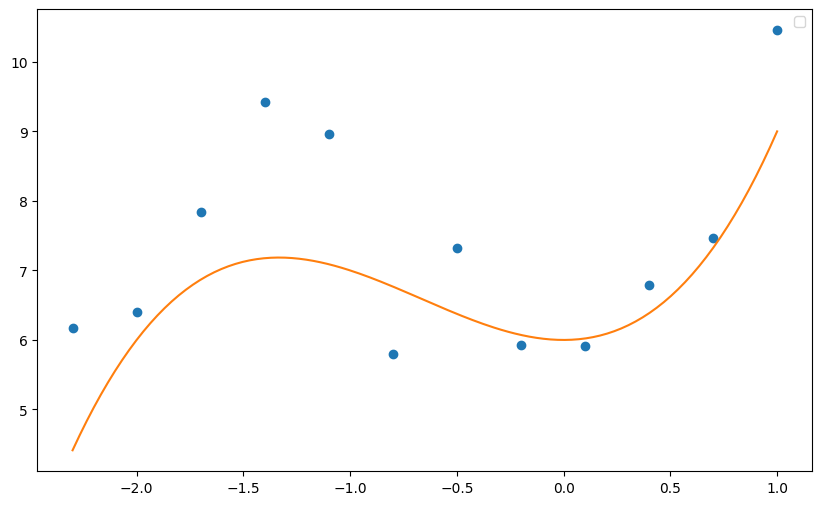

In [ ]:
x_test= np.linspace(-2.3, 1, 200) # TODO # Dense grid for the true function
y_test = f(x_test) # TODO

plt.plot(x_train, y_train, 'o') # TODO # Plot training data and true function
plt.plot(x_test, y_test)
plt.legend()
plt.show()

## (d)
Fit a straight line to the data with $y$ as output and $x$ as input and plot the predicted output $\hat{y}_{\star}$ for densely spaced $x_{\star}$ values between $-2.3$ and $1$. Plot these predictions in the same plot window.

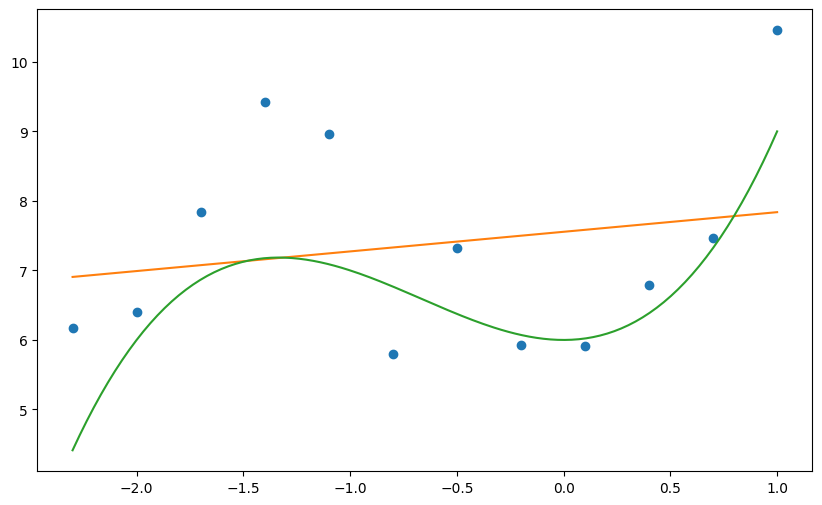

In [ ]:
x_hat = np.linspace(-2.3, 1, 200)

X_train = np.column_stack([np.ones_like(x_train),  x_train                 ])

theta_hat = np.linalg.solve( X_train.T @ X_train,X_train.T @ y_train)

X_hat = np.column_stack([np.ones_like(x_hat),x_hat])

y_hat = X_hat @ theta_hat

plt.figure(figsize=(10, 6))

plt.plot(x_train, y_train, 'o', label='Träningsdata')
plt.plot(x_hat, y_hat, '-', label='Linjär modell')
plt.plot(x_test, y_test)

plt.show()


## (e) 
Fit an 11th degree polynomial to the data with linear regression. Plot the corresponding predictions.

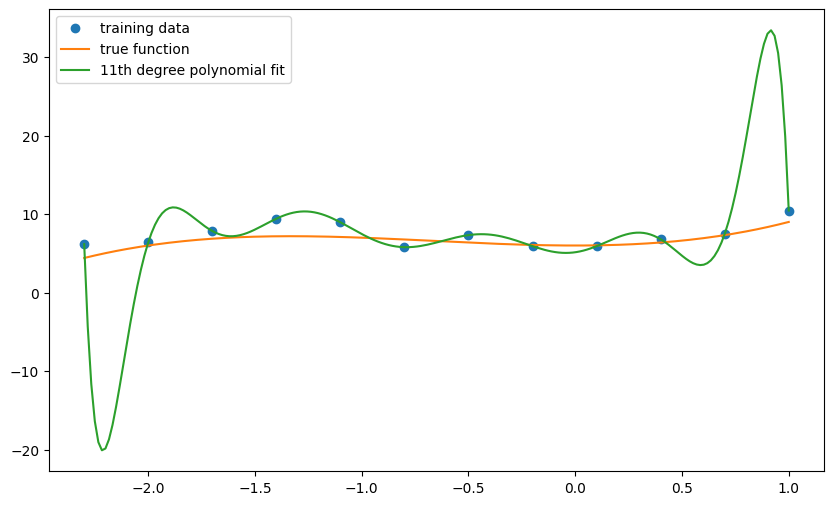

In [ ]:
# Build design matrix for 11th degree polynomial
# y = theta0 + theta1 x + ... + theta11 x^11
X_poly = np.column_stack([x_train**k for k in range(12)])

# Solve normal equations
theta_hat = np.linalg.solve(X_poly.T @ X_poly, X_poly.T @ y_train)

# Dense grid for prediction
x_hat = np.linspace(-2.3, 1, 200)
X_hat = np.column_stack([x_hat**k for k in range(12)])

# Predicted output
y_hat = X_hat @ theta_hat

# Plot training data, true function, and polynomial fit
plt.plot(x_train, y_train, 'o')
plt.plot(x_hat, y_hat)
plt.legend()
plt.show()


## (f) 

Use the fucntion `sklearn.linear_model.Ridge` and `sklearn.linear_model.Lasso` to fit a 11th degree polynomial. Also inspect the estimated coefficients. Try different values of penalty term $\alpha$. What do you observe?


Model coefficients:
α = 0
[   5.144    3.865   43.646  -21.819 -267.271 -103.32   462.677  417.661
 -115.029 -277.941 -120.208  -16.95 ]
α = 1
[ 5.256  0.193  1.688 -0.036  1.019  0.044  0.475  0.475 -0.048  0.527
  0.506  0.11 ]
α = 10
[ 2.711e+00 -2.549e-04  1.228e+00 -3.594e-02  9.091e-01  5.698e-02
  6.136e-01  3.364e-01  2.401e-01  5.728e-01  2.995e-01  4.183e-02]
α = 100
[ 0.543 -0.035  0.325 -0.08   0.319 -0.117  0.312 -0.078  0.176  0.159
 -0.086 -0.044]
α = 1000
[ 0.066 -0.012  0.048 -0.024  0.056 -0.039  0.067 -0.043  0.05   0.004
 -0.02  -0.003]


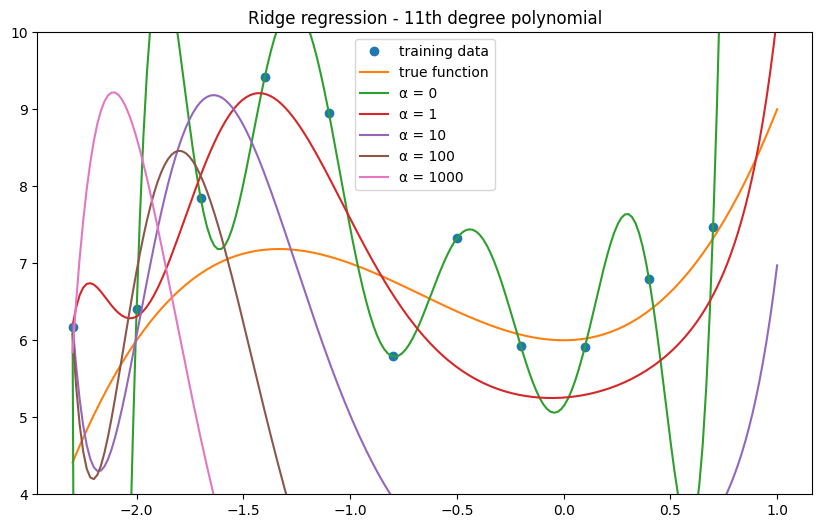

Model coefficients (Lasso):
α = 1
[ 5.826e+00  0.000e+00  0.000e+00  0.000e+00  5.556e-01 -0.000e+00
  0.000e+00 -0.000e+00  0.000e+00  3.781e-02 -0.000e+00 -5.546e-03]
α = 10
[ 0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00  0.000e+00
  0.000e+00 -0.000e+00  8.085e-02 -0.000e+00 -2.533e-05  6.008e-03]
α = 100
[ 0.     0.     0.     0.     0.    -0.     0.    -0.     0.    -0.
  0.002 -0.   ]
α = 1000
[ 0.     0.     0.     0.     0.     0.     0.     0.     0.    -0.
  0.    -0.001]


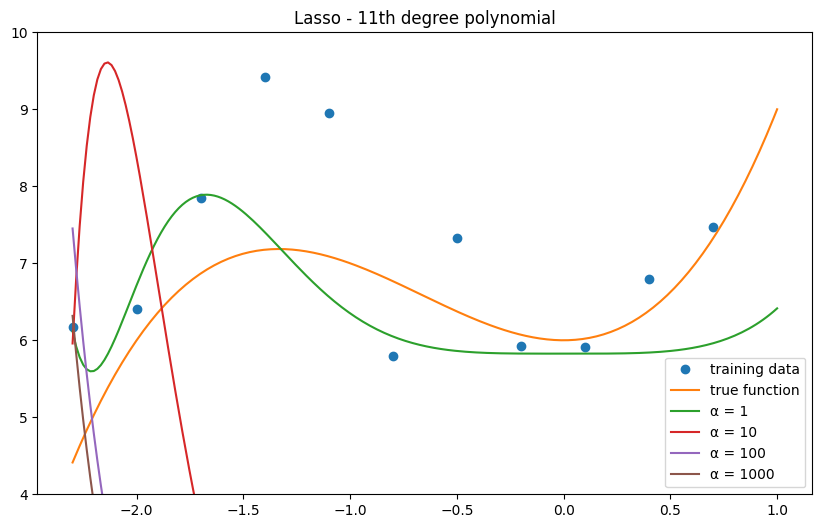

In [ ]:
# Ridge
#la till ---
X_train_poly = np.column_stack([x_train**k for k in range(12)])
X_test_poly  = np.column_stack([x_test**k  for k in range(12)])

plt.plot(x_train, y_train, 'o', label='training data')
plt.plot(x_test, y_test, label='true function')
print('Model coefficients:')
for alpha in [0, 1, 10, 100, 1000]:
    model = skl_lm.Ridge(alpha=alpha, fit_intercept=False) #TODO
    model.fit(X_train_poly, y_train) # TODO
    print(f'\u03b1 = {alpha}')
    print(model.coef_)

    prediction =  model.predict(X_test_poly) # TODO
  
    plt.plot(x_test, prediction, label=f'\u03b1 = {alpha}')

plt.title('Ridge regression - 11th degree polynomial')
plt.ylim([4,10])
plt.legend()
plt.show()

# Lasso
# do the same but use Lasso()

plt.plot(x_train, y_train, 'o', label='training data')
plt.plot(x_test, y_test, label='true function')

print('Model coefficients (Lasso):')
for alpha in [1, 10, 100, 1000]:  # Lasso requires alpha > 0
    model = skl_lm.Lasso(alpha=alpha, fit_intercept=False, max_iter=100000)
    model.fit(X_train_poly, y_train)

    print(f'α = {alpha}')
    print(model.coef_)

    prediction = model.predict(X_test_poly)
    plt.plot(x_test, prediction, label=f'α = {alpha}')

plt.title('Lasso - 11th degree polynomial')
plt.ylim([4, 10])
plt.legend()
plt.show()

# 3.6 Getting started with classification – Breast cancer diagnosis

In this exercise, we will consider the data set `data/biopsy.csv` with data from breast biopsies, for the purpose of diagnosing breast cancer. For each patient, the data set contains nine different attributes (clump thickness, uniformity of cell size, uniformity of cell shape, marginal adhesion, single epithelial cell size, bare nuclei, bland chromatin, normal nucleoli and mitoses) scored on a scale from $1$ to $10$, as well as the physician’s diagnosis (malign or benign).

## Dataset
This data frame `biopsy` contains the following columns:  
`ID`: sample code number (not unique).  
`V1`: clump thickness.  
`V2`: uniformity of cell size.  
`V3`: uniformity of cell shape.  
`V4`: marginal adhesion.  
`V5`: single epithelial cell size.  
`V6`: bare nuclei (16 values are missing).  
`V7`: bland chromatin.  
`V8`: normal nucleoli.  
`V9`: mitoses.  
`class`: "benign" or "malignant".  

## a)
Load and familiarize yourself with the data set, using, e.g.`info()`, `describe()`, `pandas.plotting.scatter_matrix()` and `print()`.

In [96]:
# url = 'data/biopsy.csv'
url = 'https://uu-sml.github.io/course-sml-public/data/biopsy.csv'
biopsy = pd.read_csv(url, na_values='?', dtype={'ID': str}).dropna().reset_index()

In [97]:
biopsy.head()

,index,ID,V1,V2,V3,V4,V5,V6,V7,V8,V9,class
0,0,1000025,5,1,1,1,2,1.0,3,1,1,benign
1,1,1002945,5,4,4,5,7,10.0,3,2,1,benign
2,2,1015425,3,1,1,1,2,2.0,3,1,1,benign
3,3,1016277,6,8,8,1,3,4.0,3,7,1,benign
4,4,1017023,4,1,1,3,2,1.0,3,1,1,benign


In [98]:
# Summary of the variables, note that it does not include the string variables
biopsy.describe()

,index,V1,V2,V3,V4,V5,V6,V7,V8,V9
count,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000,683.000000
mean,351.355783,4.442167,3.150805,3.215227,2.830161,3.234261,3.544656,3.445095,2.869693,1.603221
std,202.563927,2.820761,3.065145,2.988581,2.864562,2.223085,3.643857,2.449697,3.052666,1.732674
min,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,176.500000,2.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.000000,1.000000,1.000000
50%,355.000000,4.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,1.000000,1.000000
75%,526.500000,6.000000,5.000000,5.000000,4.000000,4.000000,6.000000,5.000000,4.000000,1.000000
max,698.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


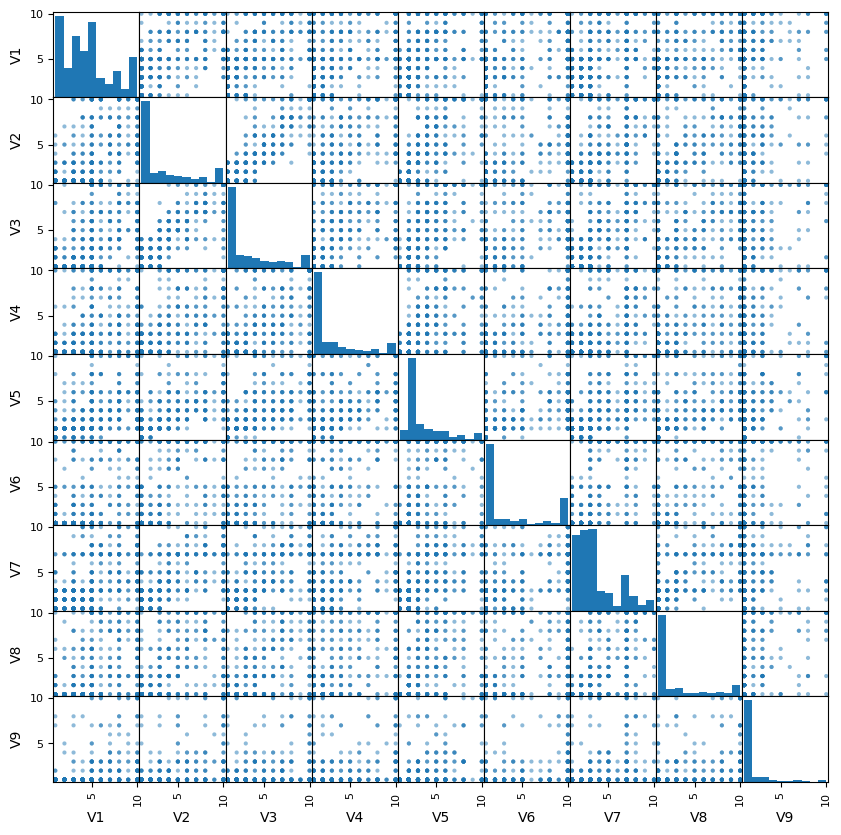

In [99]:
# scatterplot of the variables V1-V9
pd.plotting.scatter_matrix(biopsy.iloc[:, 2:11], figsize=(10,10))
plt.show()

## b)
Split the data randomly into a training set and a test set of approximately similar size.

In [ ]:
# random training set, half the data
train_idx = np.random.choice(len(biopsy), size=len(biopsy)//2, replace=False)

# remaining test set
test_idx = np.setdiff1d(np.arange(len(biopsy)), train_idx)

# the train and test datasets
train = biopsy.iloc[train_idx]
test = biopsy.iloc[test_idx]

print(len(train), len(test))

341 342


## c) Logistic regression <a id='4.1-c'></a>
Perform logistic regression with `class` as output variable and `V3`, `V4` and `V5` as input variables. Do a prediction on the test set, and compute (i) the fraction of correct predictions and (ii) the confusion matrix (using, for examnple, `pandas.crosstab()`). The commands `skl_lm.LogisticRegression()` and `model.predict()` are useful. Is the performance any good, and what does the confusion matrix tell you?

In [110]:
model = skl_lm.LogisticRegression(solver='lbfgs')

X_train = train[['V3', 'V4', 'V5']] #TODO
Y_train = train['class']
X_test = test[['V3', 'V4', 'V5']]# TODO
Y_test = test['class'] # TODO

model.fit(X_train, Y_train) # TODO
print('Model summary:')
print(model)

Model summary:
LogisticRegression()


In [119]:
predict_prob = model.predict_proba(X_test) # TODO
print('The class order in the model:')
print(model.classes_)
print('Examples of predicted probablities for the above classes:')
predict_prob[0:5]   # inspect the first 5 predictions

The class order in the model:
['benign' 'malignant']
Examples of predicted probablities for the above classes:


array([[0.99 , 0.01 ],
       [0.082, 0.918],
       [0.99 , 0.01 ],
       [0.071, 0.929],
       [0.972, 0.028]])

In [120]:
prediction = np.empty(len(X_test), dtype=object)
prediction = np.where(predict_prob[:, 0]>=0.5, 'benign', 'malignant')
prediction[0:5]  # Inspect the first 5 predictions after labeling.

array(['benign', 'malignant', 'benign', 'malignant', 'benign'],
      dtype='<U9')

In [121]:
# Confusion matrix
print("Confusion matrix:\n")
print(pd.crosstab(Y_test, prediction, rownames=['True class'], colnames=['Predicted class']))

# Accuracy
print(f"Accuracy: {np.mean(prediction == Y_test):.3f}")

Confusion matrix:

Predicted class  benign  malignant
True class                        
benign              296          8
malignant            25        158
Accuracy: 0.932


## d) LDA
Repeat [(c)](#4.1-c) using LDA. A useful command is `sklearn.discriminant_analysis.LinearDiscriminantAnalysis()`. `sklearn.discriminant_analysis` is imported as `skl_da`

In [126]:
import sklearn.discriminant_analysis as skl_da

model = skl_da.LinearDiscriminantAnalysis()
model.fit(X_train, Y_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [127]:
predict_prob = model.predict_proba(X_test)
print('The class order in the model:')

print(model.classes_)
print('Examples of predicted probablities for the above classes:')
with np.printoptions(suppress=True, precision=3): # Supress scientific notaion, e.g. 1.0e-2.
    print(predict_prob[0:5])   # inspect the first 5 predictions

The class order in the model:
['benign' 'malignant']
Examples of predicted probablities for the above classes:
[[1.    0.   ]
 [0.206 0.794]
 [1.    0.   ]
 [0.024 0.976]
 [0.999 0.001]]


In [128]:
prediction = np.empty(len(X_test), dtype=object)
prediction = np.where(predict_prob[:, 0]>=0.5, 'benign', 'malignant')
print("First five predictions:")
print(prediction[0:5], '\n')  # Inspect the first 5 predictions after labeling.

# Confusion matrix
print("Consufion matrix:")
print(pd.crosstab(prediction, Y_test),'\n')

# Accuracy
print(f"Accuracy: {np.mean(prediction == Y_test):.3f}")

First five predictions:
['benign' 'malignant' 'benign' 'malignant' 'benign'] 

Consufion matrix:
class      benign  malignant
row_0                       
benign        300         36
malignant       4        147 

Accuracy: 0.918


## e) QDA
Repeat [(c)](#4.1-c) using QDA. A useful command is `sklearn.discriminant_analysis.QuadraticDiscriminantAnalysis()`.

In [129]:
import sklearn.discriminant_analysis as skl_da

model = skl_da.QuadraticDiscriminantAnalysis()
model.fit(X_train, Y_train)

predict_prob = model.predict_proba(X_test)
print('The class order in the model:')

print(model.classes_)
print('Examples of predicted probablities for the above classes:')
with np.printoptions(suppress=True, precision=3): # Supress scientific notaion, e.g. 1.0e-2.
    print(predict_prob[0:5])   # inspect the first 5 predictions

prediction = np.empty(len(X_test), dtype=object)
prediction = np.where(predict_prob[:, 0]>=0.5, 'benign', 'malignant')
print("First five predictions:")
print(prediction[0:5], '\n')  # Inspect the first 5 predictions after labeling.

# Confusion matrix
print("Consufion matrix:")
print(pd.crosstab(prediction, Y_test),'\n')

# Accuracy
print(f"Accuracy: {np.mean(prediction == Y_test):.3f}")

The class order in the model:
['benign' 'malignant']
Examples of predicted probablities for the above classes:
[[0.999 0.001]
 [0.    1.   ]
 [0.999 0.001]
 [0.    1.   ]
 [0.993 0.007]]
First five predictions:
['benign' 'malignant' 'benign' 'malignant' 'benign'] 

Consufion matrix:
class      benign  malignant
row_0                       
benign        291         13
malignant      13        170 

Accuracy: 0.947


## f) KNN
Repeat [(c)](#4.1-c) using $k$-NN (with $k = 1$). A useful commands is `sklearn.neighbors.KNeighborsClassifier()`.

In [130]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=1)
model.fit(X_train, Y_train)

predict_prob = model.predict_proba(X_test)
print('The class order in the model:')

print(model.classes_)
print('Examples of predicted probablities for the above classes:')
with np.printoptions(suppress=True, precision=3): # Supress scientific notaion, e.g. 1.0e-2.
    print(predict_prob[0:5])   # inspect the first 5 predictions

prediction = np.empty(len(X_test), dtype=object)
prediction = np.where(predict_prob[:, 0]>=0.5, 'benign', 'malignant')
print("First five predictions:")
print(prediction[0:5], '\n')  # Inspect the first 5 predictions after labeling.

# Confusion matrix
print("Consufion matrix:")
print(pd.crosstab(prediction, Y_test),'\n')

# Accuracy
print(f"Accuracy: {np.mean(prediction == Y_test):.3f}")

The class order in the model:
['benign' 'malignant']
Examples of predicted probablities for the above classes:
[[1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [1. 0.]]
First five predictions:
['benign' 'benign' 'benign' 'malignant' 'benign'] 

Consufion matrix:
class      benign  malignant
row_0                       
benign        292         32
malignant      12        151 

Accuracy: 0.910


## g) Try different values for KNN
Use a `for`-loop to explore the performance of $k$-NN for different values of $k$, and plot the fraction of correct
predictions as a function of $k$.

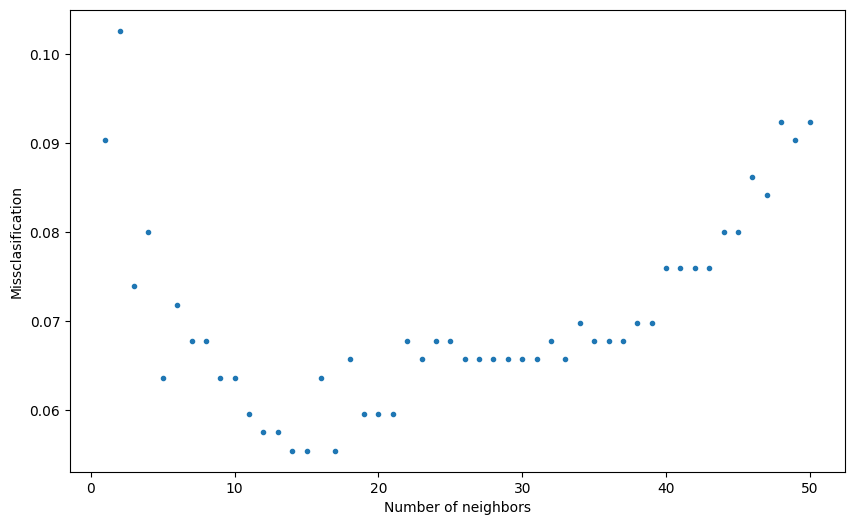

In [132]:
misclassification = []
for k in range(50):  # Try n_neighbors = 1, 2, ...., 50
    model = KNeighborsClassifier(n_neighbors=k+1) # TODO
    model.fit(X_train, Y_train) # TODO
    prediction = model.predict(X_test) # TODO
    misclassification.append(np.mean(prediction != Y_test))

K = np.linspace(1, 50, 50)
plt.plot(K, misclassification,'.')
plt.ylabel('Missclasification')
plt.xlabel('Number of neighbors')
plt.show()

## h) ROC for logistic regression
Use a `for`-loop to explore how the true and false positive rates in logistic regression are affected by different threshold values, and plot the result as a `ROC curve`. (see Figure 4.7 and Table 4.1 in the book).

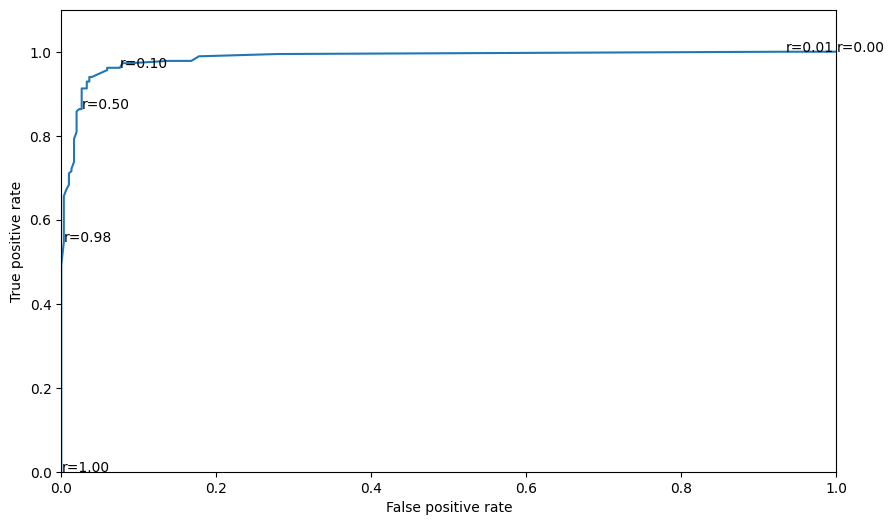

In [133]:
true_postive_rate = []
false_positive_rate = []

positive_class = 'malignant'
negative_class = 'benign'

P = np.sum(Y_test == positive_class) # Number of positive examples in test data
N = np.sum(Y_test == negative_class) # Number of negative samples in test data

threshold = np.linspace(0.00, 1, 101)
model = skl_lm.LogisticRegression(solver='lbfgs')
model.fit(X_train, Y_train)
predict_prob = model.predict_proba(X_test)
positive_class_index = np.argwhere(model.classes_ == positive_class).squeeze()

for r in threshold:
    prediction = np.where(predict_prob[:, positive_class_index] > r,
                          positive_class,
                          negative_class)
    
    FP = np.sum((prediction==positive_class)&(Y_test==negative_class)) # False Positive
    TP = np.sum((prediction==positive_class)&(Y_test==positive_class)) # True positive
    
    false_positive_rate.append(FP/N)
    true_postive_rate.append(TP/P)

plt.plot(false_positive_rate, true_postive_rate);
for idx in [0, 1, 10, 50, 98, 100]:
    plt.text(false_positive_rate[idx], true_postive_rate[idx], f"r={threshold[idx]:.2f}")
plt.xlim([0,1])
plt.ylim([0,1.1]);
plt.xlabel('False positive rate')
plt.ylabel('True positive rate');

# 3.7 Decision boundaries
The following code generates some data with $x_1$ and $x_2$ both in $[0, 10]$ and $y$ either $0$ or $1$, and plots the decision boundary for a logistic regression model.

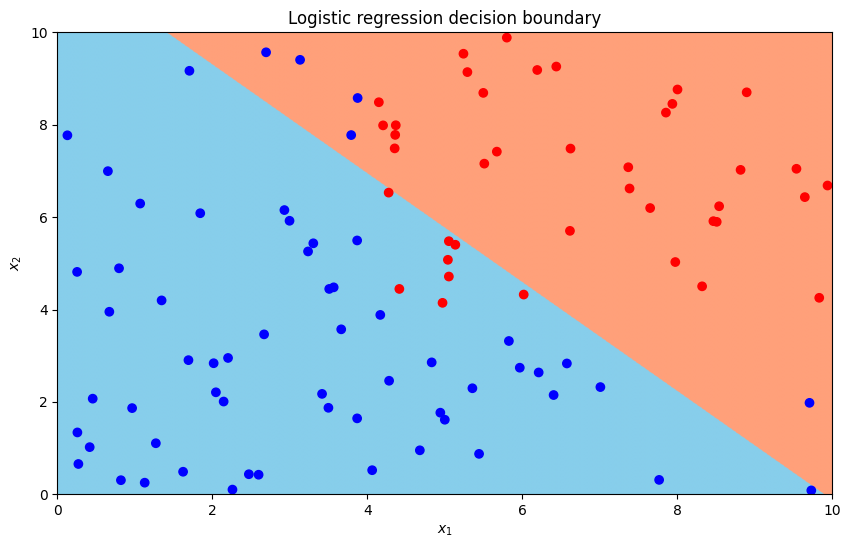

In [134]:
# generate data
np.random.seed(2)
N = 100
x1 = np.random.uniform(0, 10, N)
x2 = np.random.uniform(0, 10, N)
y = np.ones(N)
y[x1<4] = 0
y[x2<4] = 0
X = pd.DataFrame({'x1': x1, 'x2': x2})

# learn a logistic regression model
model = skl_lm.LogisticRegression(solver='lbfgs')
model.fit(X, y)

# classify the points in the whole domain
res = 0.01   # resolution of the squares
xs1 = np.arange(0, 10 + res, res)
xs2 = np.arange(0, 10 + res, res)
xs1, xs2 = np.meshgrid(xs1, xs2)    # Creating the grid for all the data points
X_all = pd.DataFrame({'x1': xs1.flatten(), 'x2': xs2.flatten()})
prediction = model.predict(X_all)

from matplotlib.colors import LinearSegmentedColormap
mycmap = LinearSegmentedColormap.from_list('mycmap', ['skyblue', 'lightsalmon'])
plt.imshow(prediction.reshape(xs1.shape[0],-1),
           cmap=mycmap,
           origin='lower',
           extent=[0,10,0,10],
           aspect='auto')

# Plot of the data points and their label
plt.scatter(x1, x2, c=y, cmap='bwr') # blue - white -red colormap

plt.title('Logistic regression decision boundary')
plt.xlim([0,10])
plt.ylim([0,10])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

## (a) 
Run the code and verify that it reproduces the figure, and make sure you understand the figure. What is the misclassification rate here?

In [ ]:
13%

## (b) 
Modify the code to plot the decision boundary for a LDA classifier. What differences do you see? What is the misclassification rate?

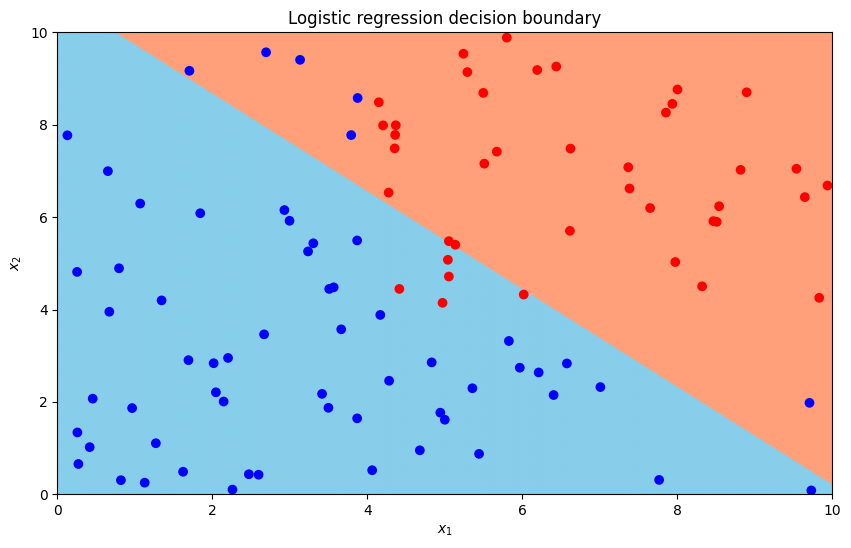

In [ ]:
import sklearn.discriminant_analysis as skl_da

# generate data
np.random.seed(2)
N = 100
x1 = np.random.uniform(0, 10, N)
x2 = np.random.uniform(0, 10, N)
y = np.ones(N)
y[x1<4] = 0
y[x2<4] = 0
X = pd.DataFrame({'x1': x1, 'x2': x2})

# learn a logistic regression model
model = skl_da.LinearDiscriminantAnalysis()
model.fit(X, y)

# classify the points in the whole domain
res = 0.01   # resolution of the squares
xs1 = np.arange(0, 10 + res, res)
xs2 = np.arange(0, 10 + res, res)
xs1, xs2 = np.meshgrid(xs1, xs2)    # Creating the grid for all the data points
X_all = pd.DataFrame({'x1': xs1.flatten(), 'x2': xs2.flatten()})
prediction = model.predict(X_all)

from matplotlib.colors import LinearSegmentedColormap
mycmap = LinearSegmentedColormap.from_list('mycmap', ['skyblue', 'lightsalmon'])
plt.imshow(prediction.reshape(xs1.shape[0],-1),
           cmap=mycmap,
           origin='lower',
           extent=[0,10,0,10],
           aspect='auto')

# Plot of the data points and their label
plt.scatter(x1, x2, c=y, cmap='bwr') # blue - white -red colormap

plt.title('Logistic regression decision boundary')
plt.xlim([0,10])
plt.ylim([0,10])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

# typ 11 eller 13

## (c) 
Modify the code to plot the decision boundary for a QDA classifier. What differences do you see? What is the misclassification rate?

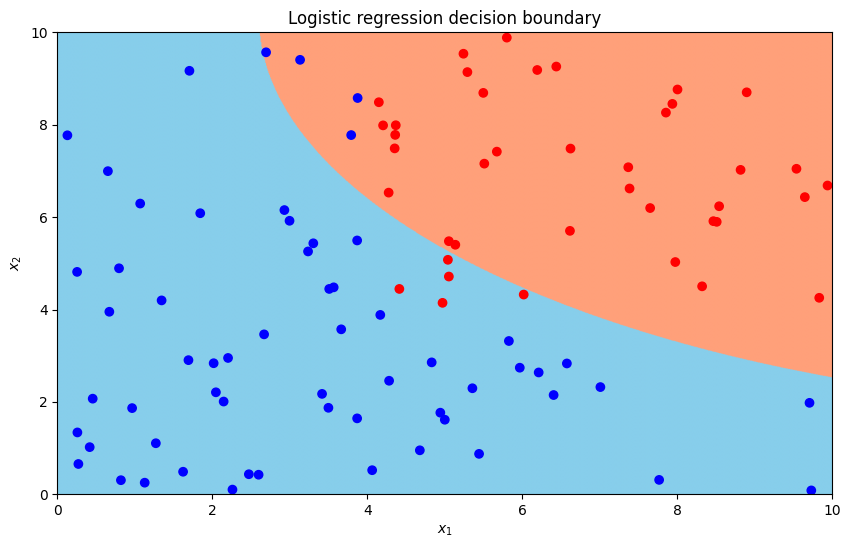

In [ ]:


# generate data
np.random.seed(2)
N = 100
x1 = np.random.uniform(0, 10, N)
x2 = np.random.uniform(0, 10, N)
y = np.ones(N)
y[x1<4] = 0
y[x2<4] = 0
X = pd.DataFrame({'x1': x1, 'x2': x2})

# learn a logistic regression model
model = skl_da.QuadraticDiscriminantAnalysis()
model.fit(X, y)

# classify the points in the whole domain
res = 0.01   # resolution of the squares
xs1 = np.arange(0, 10 + res, res)
xs2 = np.arange(0, 10 + res, res)
xs1, xs2 = np.meshgrid(xs1, xs2)    # Creating the grid for all the data points
X_all = pd.DataFrame({'x1': xs1.flatten(), 'x2': xs2.flatten()})
prediction = model.predict(X_all)

from matplotlib.colors import LinearSegmentedColormap
mycmap = LinearSegmentedColormap.from_list('mycmap', ['skyblue', 'lightsalmon'])
plt.imshow(prediction.reshape(xs1.shape[0],-1),
           cmap=mycmap,
           origin='lower',
           extent=[0,10,0,10],
           aspect='auto')

# Plot of the data points and their label
plt.scatter(x1, x2, c=y, cmap='bwr') # blue - white -red colormap

plt.title('Logistic regression decision boundary')
plt.xlim([0,10])
plt.ylim([0,10])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

# 9

## (d) 
Modify the code to plot the decision boundary for a $k$-NN classifier. What differences do you see? What is the misclassification rate?

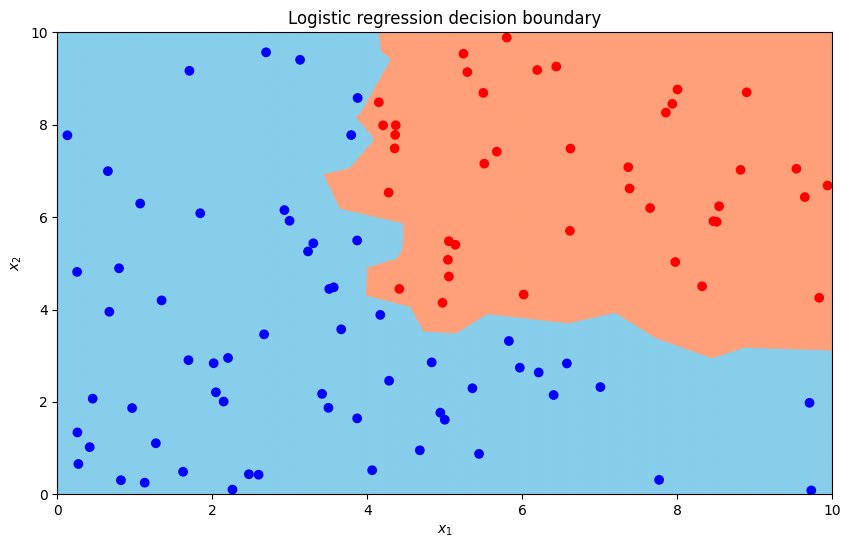

In [ ]:
# generate data
np.random.seed(2)
N = 100
x1 = np.random.uniform(0, 10, N)
x2 = np.random.uniform(0, 10, N)
y = np.ones(N)
y[x1<4] = 0
y[x2<4] = 0
X = pd.DataFrame({'x1': x1, 'x2': x2})

# learn a logistic regression model
model = KNeighborsClassifier(n_neighbors=1)
model.fit(X, y)

# classify the points in the whole domain
res = 0.01   # resolution of the squares
xs1 = np.arange(0, 10 + res, res)
xs2 = np.arange(0, 10 + res, res)
xs1, xs2 = np.meshgrid(xs1, xs2)    # Creating the grid for all the data points
X_all = pd.DataFrame({'x1': xs1.flatten(), 'x2': xs2.flatten()})
prediction = model.predict(X_all)

from matplotlib.colors import LinearSegmentedColormap
mycmap = LinearSegmentedColormap.from_list('mycmap', ['skyblue', 'lightsalmon'])
plt.imshow(prediction.reshape(xs1.shape[0],-1),
           cmap=mycmap,
           origin='lower',
           extent=[0,10,0,10],
           aspect='auto')

# Plot of the data points and their label
plt.scatter(x1, x2, c=y, cmap='bwr') # blue - white -red colormap

plt.title('Logistic regression decision boundary')
plt.xlim([0,10])
plt.ylim([0,10])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

# 0

## (e) 
What happens with the decision boundary for logistic regression if you include the term $x_1x_2$ as an input? What is the misclassification rate?

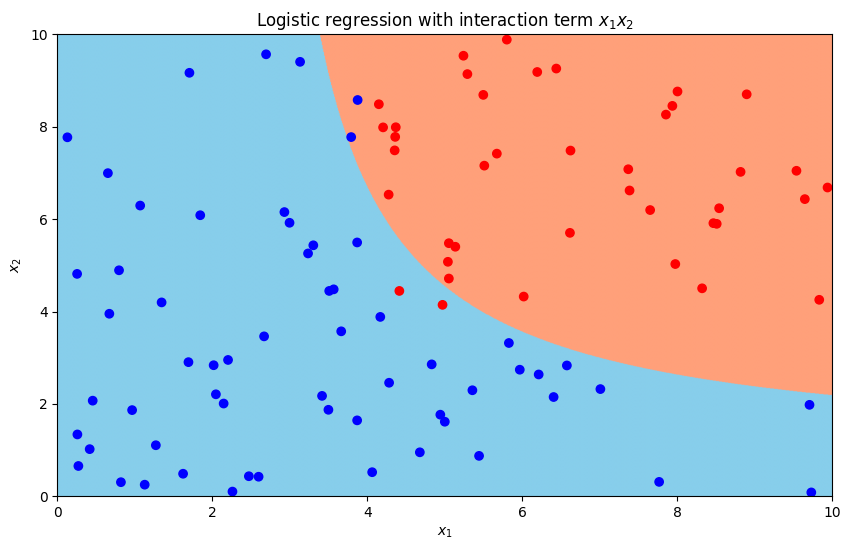

In [143]:
# generate data
np.random.seed(2)
N = 100
x1 = np.random.uniform(0, 10, N)
x2 = np.random.uniform(0, 10, N)
y = np.ones(N)
y[x1 < 4] = 0
y[x2 < 4] = 0

X = pd.DataFrame({'x1': x1, 'x2': x2})
X['x1x2'] = X['x1'] * X['x2']

# logistic regression with interaction term
model = skl_lm.LogisticRegression()
model.fit(X, y)

# classify the points in the whole domain
res = 0.01
xs1 = np.arange(0, 10 + res, res)
xs2 = np.arange(0, 10 + res, res)
xs1, xs2 = np.meshgrid(xs1, xs2)

X_all = pd.DataFrame({'x1': xs1.flatten(), 'x2': xs2.flatten()})
X_all['x1x2'] = X_all['x1'] * X_all['x2']

prediction = model.predict(X_all)

from matplotlib.colors import LinearSegmentedColormap
mycmap = LinearSegmentedColormap.from_list('mycmap', ['skyblue', 'lightsalmon'])

plt.imshow(prediction.reshape(xs1.shape[0], -1),
           cmap=mycmap,
           origin='lower',
           extent=[0, 10, 0, 10],
           aspect='auto')

plt.scatter(x1, x2, c=y, cmap='bwr')
plt.title('Logistic regression with interaction term $x_1x_2$')
plt.xlim([0, 10])
plt.ylim([0, 10])
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.show()

# 4 fault


# 3.8 Multiclass classification
In the course, we have focused on the classification problem for 2 classes. The methods can, however, be generalized to more than two classes. In `Python`, the commands `skl_da.LinearDiscriminantAnalysis()`, `skl_da.QuadraticDiscriminantAnalysis()` and `skl_nb.KNeighborsClassifier()` can all be used directly for multi-class problems as well, which we will do in this exercise.

## (a)
Load and familiarize yourself with the data set `iris`, and split it randomly into a training and a test data set.

**Description**

This famous (Fisher's or Anderson's) `iris` data set gives the measurements in centimeters of the variables sepal length and width and petal length and width, respectively, for $50$ flowers from each of $3$ species of iris. The species are Iris setosa, versicolor, and virginica.

**Format**

iris is a data frame with $150$ cases (rows) and $5$ variables (columns) named `Sepal.Length`, `Sepal.Width`, `Petal.Length`, `Petal.Width`, and `Species`.

In [144]:
# url = 'data/iris.csv'
url = 'https://uu-sml.github.io/course-sml-public/data/iris.csv'
iris = pd.read_csv(url)

In [145]:
# sampling indices for training
np.random.seed(1)
iris.info()
trainI = np.random.choice(iris.shape[0], size=100, replace=False)
trainIndex = iris.index.isin(trainI)
iris_train = iris.iloc[trainIndex]  # training set
iris_test = iris.iloc[~trainIndex]  # test set

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Sepal.Length  150 non-null    float64
 1   Sepal.Width   150 non-null    float64
 2   Petal.Length  150 non-null    float64
 3   Petal.Width   150 non-null    float64
 4   Species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


## (b)
Use all inputs (`Sepal.Length`, `Sepal.Width`, `Petal.Length`, `Petal.Width`) to predict the output `Species` (`setosa`,
`versicolor` and `virginica`) using LDA, QDA, and $k$-NN, respectively.

In [ ]:
input_variables = ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width'] # TODO

X_train = iris_train[input_variables]
Y_train = iris_train['Species'] # TODO
X_test = iris_test[input_variables] # TODO
Y_test = iris_test['Species']

# LDA
model = skl_da.LinearDiscriminantAnalysis()
model.fit(X_train, Y_train)
prediction = model.predict(X_test)
print(f"Accuracy LDA: {np.mean(prediction == Y_test)}")

# QDA
# TODO
# QDA
model = skl_da.QuadraticDiscriminantAnalysis()
model.fit(X_train, Y_train)
prediction = model.predict(X_test)
print(f"Accuracy QDA: {np.mean(prediction == Y_test):.3f}")

# KNN
# TODO
model = KNeighborsClassifier(n_neighbors=1)
model.fit(X_train, Y_train)
prediction = model.predict(X_test)
print(f"Accuracy k-NN: {np.mean(prediction == Y_test):.3f}")

Accuracy LDA: 0.96
Accuracy QDA: 0.940
Accuracy k-NN (k=5): 0.920
